# Single-Stock Risk Report

A parameterized report for one stock over one date window, built from the validated
`ohlc_hw_cleaned` table produced by `01_data_cleaning.ipynb`. Papermill can run it for any ticker by
replacing the tagged parameters cell (`03_run_all_stocks.py` does this for every stock).

**Conventions**

* Prices: **adjusted close** (splits and dividends), so returns and drawdown reflect what a holder earned.
* Returns: daily **log returns** `log(P_t / P_{t-1})` for volatility, Sharpe and the daily statistics.
* Annualization: 252 trading days; risk-free rate 2% per year (course convention).
* All metrics are kept as **fractions**; they are formatted as percentages only for display.
* Undefined metrics (too few returns, zero volatility, empty subsets) are `NaN` and displayed as `N/A`.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

## Parameters

The next cell carries the Jupyter cell tag **`parameters`**; papermill inserts an `injected-parameters`
cell after it with the values for each run. `db_path` is relative to this notebook's folder.

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Working database containing ohlc_hw_cleaned

In [3]:
# Parameters
ticker = "NKE"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/anjalibandewar/Downloads/HW2_restart/data/data.db"


## Metric functions

These functions are pure (no plotting, no database access). `tests/test_report_template.py` extracts
this cell by its `report-functions` tag and unit-tests it on hand-checkable inputs.

In [4]:
TRADING_DAYS = 252
RISK_FREE_RATE = 0.02
VOL_WINDOW = 20
MA_WINDOW = 50


def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns.

    ``log(P_t / P_{t-1})``. The first value is NaN because there is no previous
    price; it is undefined, not a zero-return day.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = VOL_WINDOW) -> pd.Series:
    """Calculate annualized rolling volatility.

    Sample standard deviation (ddof=1) of the last ``window`` daily returns,
    times sqrt(252). A full window of returns is required, so with a leading
    NaN return the first value appears at the ``window + 1``-th price; the
    warm-up stays NaN (it is never filled with zero).
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.

    ``(price - running_max) / running_max`` as a fraction <= 0. It recovers
    toward 0 as prices rise; the maximum drawdown is ``drawdown.min()``.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = RISK_FREE_RATE) -> float:
    """Calculate annualized Sharpe ratio.

    ``(mean_return * 252 - rf) / (std_return * sqrt(252))`` on nonmissing daily
    returns (sample std). Returns NaN for fewer than two returns or zero
    volatility, where the ratio is undefined.
    """
    r = returns.dropna()
    if len(r) < 2:
        return np.nan
    std = r.std()
    if not np.isfinite(std) or std <= 1e-12:
        return np.nan
    return (r.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))


def summary_metrics(prices: pd.Series, returns: pd.Series, drawdown: pd.Series,
                    risk_free_rate: float = RISK_FREE_RATE) -> dict:
    """The ten report metrics as fractions (NaN when undefined).

    * Total return: last / first adjusted close - 1.
    * Annualized return (compounded): exp(sum(log returns) * 252 / n) - 1,
      with n nonmissing log returns.
    * Annualized volatility (whole period): std(log returns) * sqrt(252);
      distinct from the *mean rolling* volatility used in the portfolio summary.
    * Best/worst day and average up/down day use log returns.
    * Positive days: positive returns / all nonmissing returns (zero days count
      in the denominator).
    """
    r = returns.dropna()
    n = len(r)
    up, down = r[r > 0], r[r < 0]
    return {
        "Total Return": prices.iloc[-1] / prices.iloc[0] - 1 if len(prices) else np.nan,
        "Annualized Return": np.exp(r.sum() * TRADING_DAYS / n) - 1 if n else np.nan,
        "Annualized Volatility": r.std() * np.sqrt(TRADING_DAYS) if n > 1 else np.nan,
        "Sharpe Ratio": calculate_sharpe_ratio(r, risk_free_rate),
        "Maximum Drawdown": drawdown.min() if len(drawdown) else np.nan,
        "Best Day": r.max() if n else np.nan,
        "Worst Day": r.min() if n else np.nan,
        "Positive Days": len(up) / n if n else np.nan,
        "Average Up Day": up.mean() if len(up) else np.nan,
        "Average Down Day": down.mean() if len(down) else np.nan,
    }

Quick checks on numbers small enough to verify by hand. For prices 80 → 100 → 70 → 85 the worst
drawdown is −30% (100 → 70) while the final drawdown is only −15%: drawdown recovers, maximum drawdown
does not.

In [5]:
check_prices = pd.Series([80.0, 100.0, 70.0, 85.0])
check_dd = calculate_max_drawdown(check_prices)
assert np.isclose(check_dd.min(), -0.30) and np.isclose(check_dd.iloc[-1], -0.15)
assert np.isnan(calculate_returns(check_prices).iloc[0])
assert np.isclose(calculate_returns(check_prices).iloc[1], np.log(100 / 80))
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01] * 30)))  # zero volatility -> undefined
print("drawdown:", check_dd.round(4).tolist(), "| worst:", check_dd.min(), "| final:", check_dd.iloc[-1])

drawdown: [0.0, 0.0, -0.3, -0.15] | worst: -0.3 | final: -0.15


## Load the cleaned data

Rows come from `ohlc_hw_cleaned` for the requested window (inclusive), opened **read-only**. The data
are validated before any calculation; the report stops with a clear error if the input cannot support
it. A 20-day volatility needs 20 returns, and 20 returns need at least **21 prices**.

In [6]:
MIN_PRICES = VOL_WINDOW + 1


def load_prices(ticker: str, start_date: str, end_date: str, db_path: str) -> pd.DataFrame:
    """Load one ticker's cleaned daily rows between two ISO dates (inclusive), indexed by date."""
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError(f"start_date {start_date} is after end_date {end_date}.")
    path = Path(db_path)
    if not path.is_file():
        raise FileNotFoundError(f"Database not found: {path.resolve()}")
    query = """
        SELECT ts, open, high, low, close, adj_close, volume, repair_flags, return_outlier
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
    """
    with closing(sqlite3.connect(path.resolve().as_uri() + "?mode=ro", uri=True)) as conn:
        frame = pd.read_sql_query(query, conn, parse_dates=["ts"],
                                  params=(ticker.strip().upper(), start.strftime("%Y-%m-%d"),
                                          end.strftime("%Y-%m-%d")))
    return frame.set_index("ts")


def validate_prices(prices: pd.DataFrame, ticker: str, min_prices: int = MIN_PRICES) -> None:
    """Raise ValueError if the loaded data cannot support the report."""
    if prices.empty:
        raise ValueError(f"No cleaned data for {ticker} between {start_date} and {end_date}.")
    problems = []
    if prices.index.has_duplicates or not prices.index.is_monotonic_increasing:
        problems.append("dates are duplicated or out of order")
    adj = prices["adj_close"]
    if adj.isna().any() or not np.isfinite(adj).all() or (adj <= 0).any():
        problems.append("adjusted close has missing, non-finite or nonpositive values")
    if problems:
        raise ValueError(f"{ticker}: invalid input data: " + "; ".join(problems))
    if len(prices) < min_prices:
        raise ValueError(
            f"Insufficient history for {ticker}: {len(prices)} prices between {start_date} and "
            f"{end_date}; at least {min_prices} are needed for {min_prices - 1} returns.")

In [7]:
prices = load_prices(ticker, start_date, end_date, db_path)
validate_prices(prices, ticker)
data_quality_ok = True  # validate_prices raised otherwise

first_obs, last_obs = prices.index[0], prices.index[-1]
print(f"{ticker} from {start_date} to {end_date}: {len(prices)} trading days")
print(f"Observed coverage: {first_obs:%Y-%m-%d} to {last_obs:%Y-%m-%d}")
coverage_note = ""
if last_obs < pd.Timestamp(end_date) - pd.Timedelta(days=7):
    coverage_note = (f"Data for {ticker} end on {last_obs:%Y-%m-%d}, before the requested end "
                     f"{end_date}; prices are not extrapolated past the last observation.")
    print("Note:", coverage_note)
repaired_rows = int(prices["repair_flags"].ne("").sum())
print(f"Rows repaired during cleaning: {repaired_rows}; days flagged as 3-sigma return outliers: "
      f"{int(prices['return_outlier'].sum())}")
display(prices.head())
display(prices.tail())

NKE from 2024-06-01 to 2024-11-30: 126 trading days
Observed coverage: 2024-06-03 to 2024-11-29
Rows repaired during cleaning: 5; days flagged as 3-sigma return outliers: 3


,open,high,low,close,adj_close,volume,repair_flags,return_outlier
ts,,,,,,,,
2024-06-03,94.52,95.25,94.05,94.40,93.50,9668106,,0
2024-06-04,94.29,95.11,93.41,94.74,93.84,7838435,,0
2024-06-05,95.32,95.32,93.70,94.32,93.42,7463300,,0
2024-06-06,94.86,96.80,93.99,95.72,94.81,9760100,,0
2024-06-07,95.39,97.94,95.30,96.55,95.63,9397400,,0


,open,high,low,close,adj_close,volume,repair_flags,return_outlier
ts,,,,,,,,
2024-11-22,76.13,77.50,75.83,77.40,77.01,12248600,,0
2024-11-25,78.50,79.86,78.41,79.26,78.86,18328919,,0
2024-11-26,78.90,78.90,77.57,77.61,77.22,9495649,,0
2024-11-27,77.61,79.05,77.59,78.34,77.94,8713504,,0
2024-11-29,78.20,79.18,78.03,78.77,78.37,7123500,,0


## Risk metrics

In [8]:
adj_close = prices["adj_close"]
returns = calculate_returns(adj_close)
volatility = calculate_volatility(returns, VOL_WINDOW)
drawdown = calculate_max_drawdown(adj_close)
moving_average = adj_close.rolling(MA_WINDOW).mean()  # NaN until 50 prices exist
sharpe = calculate_sharpe_ratio(returns)

print(f"Daily log returns: {returns.count()} (first is undefined)")
print(f"Rolling volatility estimates: {volatility.count()} ({VOL_WINDOW}-return warm-up excluded)")
print(f"Mean rolling volatility: {volatility.mean():.2%}")
print(f"Maximum drawdown: {drawdown.min():.2%} on {drawdown.idxmin():%Y-%m-%d}")
print(f"Sharpe ratio: {sharpe:.2f}" if np.isfinite(sharpe) else "Sharpe ratio: N/A")

Daily log returns: 125 (first is undefined)
Rolling volatility estimates: 106 (20-return warm-up excluded)
Mean rolling volatility: 37.30%
Maximum drawdown: -26.85% on 2024-07-24
Sharpe ratio: -0.90


## Visual report

* **Price:** each segment is colored by the 20-day volatility at its end date — red above the report's
  mean rolling volatility, green at or below it, gray during the warm-up when no estimate exists. This
  coloring is retrospective (the mean uses the whole window).
* **Daily returns:** green bars for gains, red for losses.
* **Rolling volatility:** shaded red above its mean, green below.
* **Drawdown:** layered transparent red fills give the gradient; the worst point is marked.

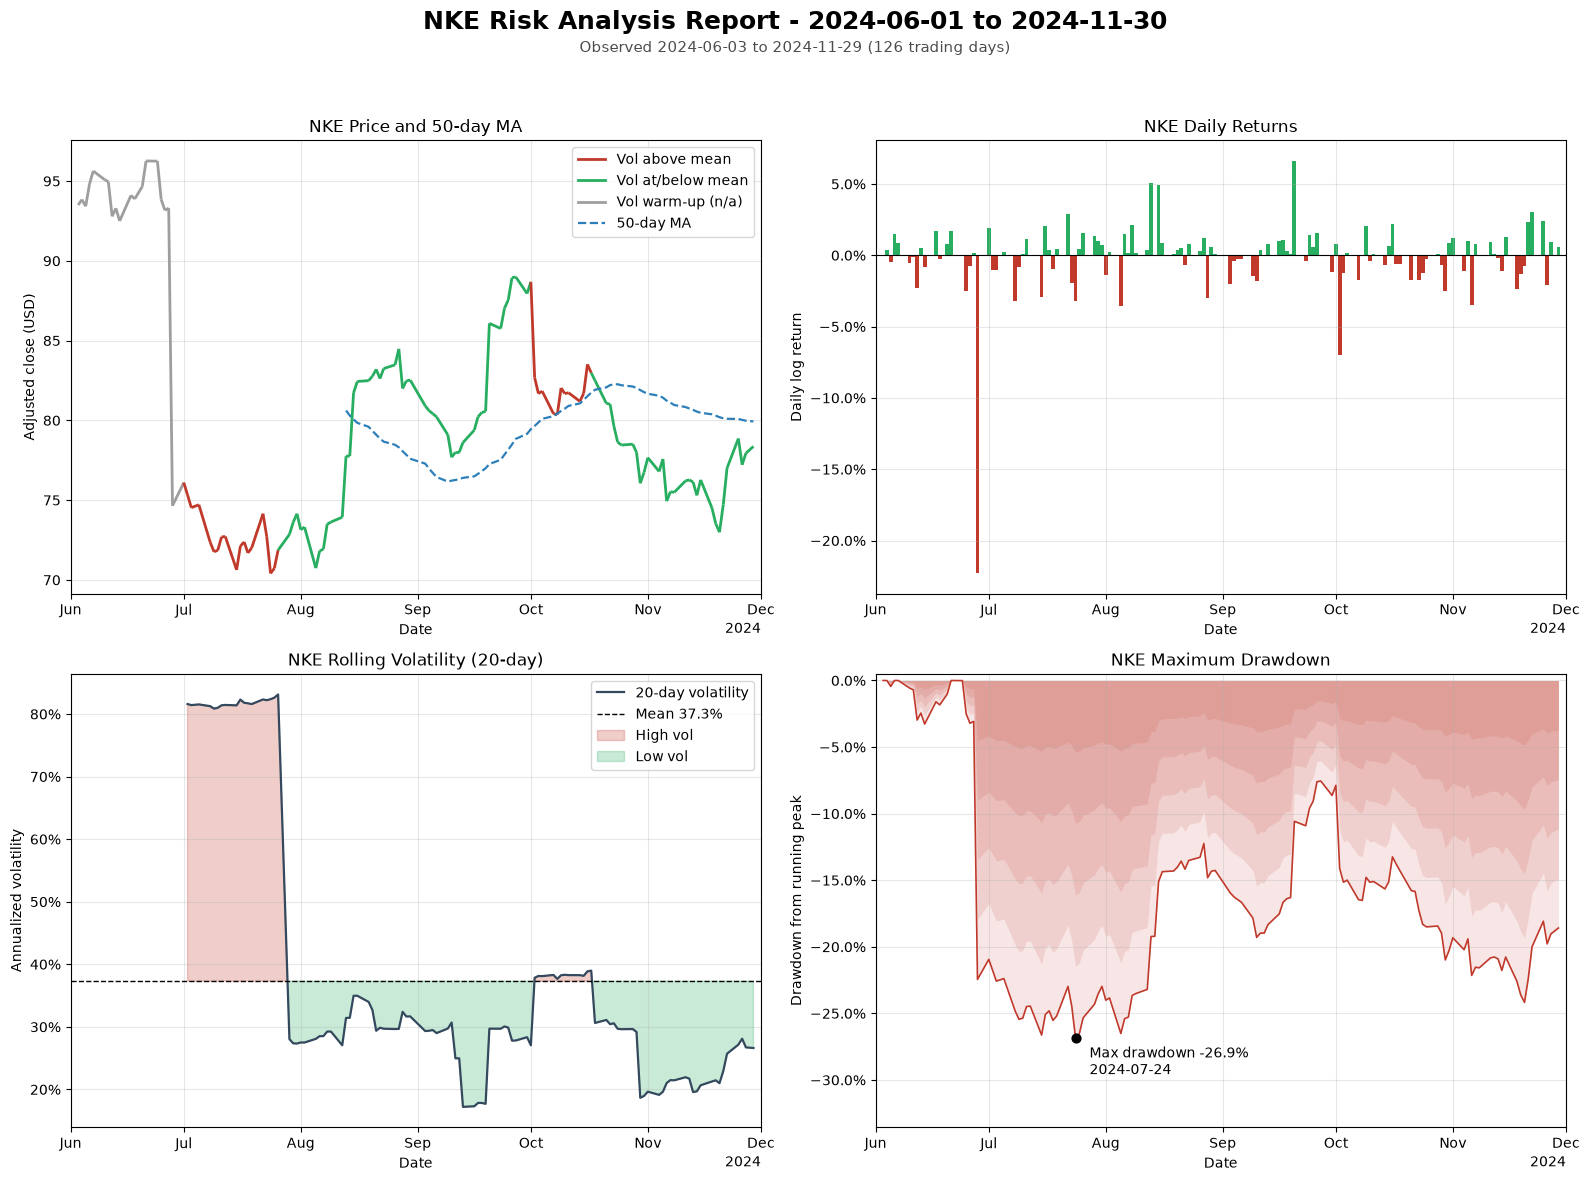

In [9]:
COLORS = {"high": "#c0392b", "low": "#27ae60", "warmup": "#9e9e9e", "line": "#34495e",
          "ma": "#2c7fb8", "drawdown": "#c0392b"}
date_fmt = mdates.ConciseDateFormatter(mdates.AutoDateLocator())

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax_price, ax_ret, ax_vol, ax_dd = axes.flat
mean_vol = volatility.mean()

# Top left: price colored by volatility regime, with the 50-day moving average.
x = mdates.date2num(adj_close.index.to_pydatetime())
points = np.column_stack([x, adj_close.to_numpy()])
segments = np.stack([points[:-1], points[1:]], axis=1)
segment_vol = volatility.to_numpy()[1:]
segment_colors = np.where(np.isnan(segment_vol), COLORS["warmup"],
                          np.where(segment_vol > mean_vol, COLORS["high"], COLORS["low"]))
ax_price.plot(adj_close.index, adj_close, alpha=0)  # sets the date axis and limits
ax_price.add_collection(LineCollection(segments, colors=segment_colors, linewidths=2))
ax_price.plot(moving_average.index, moving_average, color=COLORS["ma"], lw=1.6, ls="--")
if moving_average.count() == 0:
    ax_price.text(0.02, 0.04, f"50-day MA unavailable: only {len(adj_close)} prices (needs {MA_WINDOW})",
                  transform=ax_price.transAxes, fontsize=10, color=COLORS["ma"])
ax_price.legend(handles=[
    Line2D([], [], color=COLORS["high"], lw=2, label="Vol above mean"),
    Line2D([], [], color=COLORS["low"], lw=2, label="Vol at/below mean"),
    Line2D([], [], color=COLORS["warmup"], lw=2, label="Vol warm-up (n/a)"),
    Line2D([], [], color=COLORS["ma"], lw=1.6, ls="--", label="50-day MA"),
], loc="best")
ax_price.set(title=f"{ticker} Price and 50-day MA", xlabel="Date", ylabel="Adjusted close (USD)")

# Top right: daily log returns.
bar_colors = np.where(returns > 0, COLORS["low"], np.where(returns < 0, COLORS["high"], COLORS["warmup"]))
ax_ret.bar(returns.index, returns.fillna(0), color=bar_colors, width=1.0)
ax_ret.axhline(0, color="black", lw=0.8)
ax_ret.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_ret.set(title=f"{ticker} Daily Returns", xlabel="Date", ylabel="Daily log return")

# Bottom left: rolling volatility vs its mean.
ax_vol.plot(volatility.index, volatility, color=COLORS["line"], lw=1.6, label="20-day volatility")
ax_vol.axhline(mean_vol, color="black", ls="--", lw=1, label=f"Mean {mean_vol:.1%}")
ax_vol.fill_between(volatility.index, volatility, mean_vol, where=volatility > mean_vol,
                    color=COLORS["high"], alpha=0.25, interpolate=True, label="High vol")
ax_vol.fill_between(volatility.index, volatility, mean_vol, where=volatility < mean_vol,
                    color=COLORS["low"], alpha=0.25, interpolate=True, label="Low vol")
ax_vol.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_vol.legend(loc="best")
ax_vol.set(title=f"{ticker} Rolling Volatility (20-day)", xlabel="Date", ylabel="Annualized volatility")

# Bottom right: drawdown with layered red fills (darker near zero) and the worst point.
for depth in np.linspace(0.2, 1.0, 5):
    ax_dd.fill_between(drawdown.index, drawdown * depth, 0, color=COLORS["drawdown"], alpha=0.12, lw=0)
ax_dd.plot(drawdown.index, drawdown, color=COLORS["drawdown"], lw=1.2)
worst_date, worst = drawdown.idxmin(), drawdown.min()
ax_dd.scatter([worst_date], [worst], color="black", zorder=3, s=40)
ax_dd.annotate(f"Max drawdown {worst:.1%}\n{worst_date:%Y-%m-%d}", (worst_date, worst),
               xytext=(10, -5), textcoords="offset points", va="top", fontsize=10)
ax_dd.set_ylim(min(worst * 1.25, -0.01), 0.005)
ax_dd.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_dd.set(title=f"{ticker} Maximum Drawdown", xlabel="Date", ylabel="Drawdown from running peak")

pad = pd.Timedelta(days=2)
for ax in axes.flat:
    ax.set_xlim(first_obs - pad, last_obs + pad)  # same observed window on every panel
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(date_fmt)

fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
fig.text(0.5, 0.945, f"Observed {first_obs:%Y-%m-%d} to {last_obs:%Y-%m-%d} ({len(prices)} trading days)"
         + (f" - {coverage_note}" if coverage_note else ""), ha="center", fontsize=11, color="0.3")
fig.tight_layout(rect=[0, 0, 1, 0.935])

assert tuple(fig.get_size_inches()) == (16, 12) and len(fig.axes) == 4
plt.show()

## Summary statistics

In [10]:
stats = summary_metrics(adj_close, returns, drawdown)
DISPLAY_FORMAT = {
    "Total Return": "{:+.2%}", "Annualized Return": "{:+.2%}", "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio": "{:.2f}", "Maximum Drawdown": "{:+.2%}", "Best Day": "{:+.2%}",
    "Worst Day": "{:+.2%}", "Positive Days": "{:.1%}", "Average Up Day": "{:+.2%}",
    "Average Down Day": "{:+.2%}",
}
summary_table = pd.DataFrame({
    "Metric": list(stats),
    "Value": [DISPLAY_FORMAT[name].format(value) if np.isfinite(value) else "N/A"
              for name, value in stats.items()],
})
print(summary_table.to_string(index=False))
if coverage_note:
    print("\n" + coverage_note)

               Metric   Value
         Total Return -16.18%
    Annualized Return -29.94%
Annualized Volatility  41.82%
         Sharpe Ratio   -0.90
     Maximum Drawdown -26.85%
             Best Day  +6.62%
            Worst Day -22.30%
        Positive Days   56.0%
       Average Up Day  +1.10%
     Average Down Day  -1.75%


**Reading the report.** Total return is the simple change in adjusted price over the observed window;
annualized return compounds the average daily log return to a yearly rate, so short windows can produce
large annualized figures. Annualized volatility is the whole-period dispersion of daily returns. Sharpe
compares excess annualized return with that volatility (above 1 is strong for a single stock; negative
means the stock underperformed the 2% risk-free rate). Maximum drawdown is the worst peak-to-trough loss
within the window. Compare stocks only over the same observed dates.

## Saving results for the batch run

`sb.glue` stores named values inside the executed notebook, so `03_run_all_stocks.py` can collect them
without recomputing. Metrics are plain fractions; undefined values are stored as `None` (JSON has no
NaN). `avg_daily_return` is the mean daily log return and `avg_volatility` the mean 20-day rolling
volatility, as the portfolio summary requires.

In [11]:
def json_number(value):
    """Plain float for Scrapbook; None when the value is NaN or infinite."""
    return float(value) if value is not None and np.isfinite(value) else None


scraps = {
    "ticker": ticker.strip().upper(),
    "start_date": start_date,
    "end_date": end_date,
    "first_date": f"{first_obs:%Y-%m-%d}",
    "last_date": f"{last_obs:%Y-%m-%d}",
    "trading_days": int(len(prices)),
    "return_count": int(returns.count()),
    "data_quality_ok": data_quality_ok,
    "avg_daily_return": json_number(returns.mean()),
    "avg_volatility": json_number(volatility.mean()),
    "max_drawdown": json_number(stats["Maximum Drawdown"]),
    "sharpe_ratio": json_number(stats["Sharpe Ratio"]),
    "total_return": json_number(stats["Total Return"]),
    "annualized_return": json_number(stats["Annualized Return"]),
    "annualized_volatility": json_number(stats["Annualized Volatility"]),
}
for name, value in scraps.items():
    sb.glue(name, value)
sb.glue("summary_metrics", {name: json_number(value) for name, value in stats.items()})
print("Saved scraps:", ", ".join(list(scraps) + ["summary_metrics"]))

Saved scraps: ticker, start_date, end_date, first_date, last_date, trading_days, return_count, data_quality_ok, avg_daily_return, avg_volatility, max_drawdown, sharpe_ratio, total_return, annualized_return, annualized_volatility, summary_metrics
